Olá, **Maria Clara**!

O meu nome é **César Malaguti** e sou o revisor do seu projeto. Quando identificar um erro pela primeira vez, apenas vou apontá-lo para que você mesmo possa encontrá-lo e corrigi-lo. Ao longo do notebook farei observações e comentários sobre as suas análises, para te preparar para atuar como **Analista de Dados**. **Por favor, não mova, modifique ou exclua meus comentários.**

Você vai encontrar meus comentários em caixas coloridas:
<div class="alert alert-block alert-success"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Sucesso.</div>
<div class="alert alert-block alert-warning"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Atenção (sugestão).</div>
<div class="alert alert-block alert-danger"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Precisa de correção.</div>

Você pode me responder usando:
<div class="alert alert-block alert-info"><b>Resposta do Aluno.</b> <a class="tocSkip"></a></div>

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

<b>Comentário geral:</b> Maria Clara, parabéns! Seu projeto está aprovado. Você carregou os dados das consultas SQL, montou os gráficos das empresas e dos bairros, e conduziu o teste de hipótese formulando H0 e H1, com o teste t e a interpretação correta do p-valor. Deixei avisos em amarelo com sugestões. Bom trabalho!
</div>

# Projeto: Análise de Dados de Táxis da Zuber

## 1. Importação das bibliotecas necessárias

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

## 2. Carregamento dos dados e exploração inicial

In [42]:
# Carregamento dos dados
company = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/learning-materials/data-analyst-eng/moved_project_sql_result_01.csv')
location = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/learning-materials/data-analyst-eng/moved_project_sql_result_04.csv')
weather= pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/learning-materials/data-analyst-eng/moved_project_sql_result_07.csv')

In [43]:
# Exploração inicial
company.info()
print('------------------------------------------------------')
location.info()
print('------------------------------------------------------')
weather.info()

print(company.head())
print(location.head())
print(weather.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB
------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0  

In [44]:
# Verificação da existência de duplicados nas duas tabelas
print("Duplicados em empresas:", company.duplicated().sum())
print("Duplicados em bairros:", location.duplicated().sum())
print("Duplicados em tempo:",weather.duplicated().sum())

# Arredondamento e conversão da média de viagens para números inteiros
location['average_trips'] = location['average_trips'].round().astype(int)

# Confirmação do resultado
print("\n--- Bairros após ajuste de tipo ---")
print(location.head())

Duplicados em empresas: 0
Duplicados em bairros: 0
Duplicados em tempo: 197

--- Bairros após ajuste de tipo ---
  dropoff_location_name  average_trips
0                  Loop          10727
1           River North           9524
2         Streeterville           6665
3             West Loop           5164
4                O'Hare           2547


#### Observações:
Os três conjuntos de dados (company e location) foram importados com sucesso e renomeados para otimizar o código.
A inspeção inicial revelou que não existem valores ausentes em nenhuma das tabelas.
A verificação confirmou a ausência de linhas duplicadas nas duas primeiras tabelas, garantindo a integridade dos dados coletados.
Na terceira tabela ('weather') verificou-se a existência de 197 duplicados. Contudo, como a tabela não possui ID único de viagem, é esperado que múltiplas corridas iniciadas no mesmo horário e com o mesmo clima tenham durações idênticas. Optou-se então por não as eliminar, uma vez que poderia resultar na perda de dados reais e legítimos.
Os valores da coluna 'average_trips' da tabela 'location' foram arredondados e convertidos com sucesso de número decimal (float64) para número inteiro (int64), dado que representam uma média de viagens completas.

## 3. Análise exploratória de dados

In [45]:
# Ordenação dos bairros por média de viagens e seleção dos 10 primeiros
top_10_locations = location.sort_values(by='average_trips', ascending=False).head(10)

# Exibição o resultado
print("--- Top 10 Bairros com Mais Destinos ---")
print(top_10_locations)

--- Top 10 Bairros com Mais Destinos ---
  dropoff_location_name  average_trips
0                  Loop          10727
1           River North           9524
2         Streeterville           6665
3             West Loop           5164
4                O'Hare           2547
5             Lake View           2421
6            Grant Park           2069
7         Museum Campus           1510
8            Gold Coast           1364
9    Sheffield & DePaul           1260


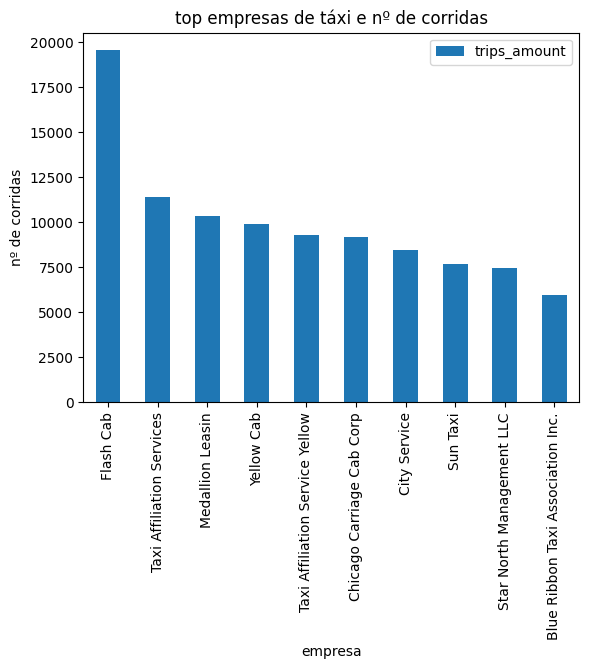

In [46]:

# Gráfico das Empresas de Táxi e nº de corridas
top_companies = company.sort_values(by='trips_amount', ascending=False).head(10)
top_companies.plot(kind='bar',title='top empresas de táxi e nº de corridas',xlabel='empresa',ylabel='nº de corridas',x='company_name')
plt.show()


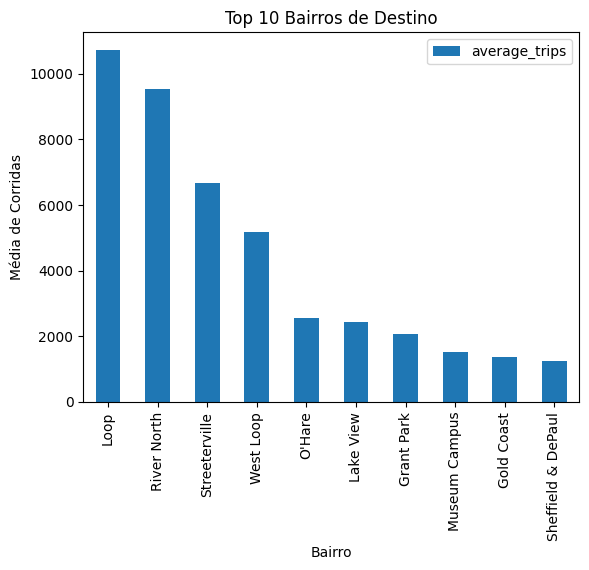

In [47]:
# Gráfico do Top 10 Bairros de Destino
top_10_locations.plot(kind='bar',x='dropoff_location_name',title='Top 10 Bairros de Destino',xlabel='Bairro',ylabel='Média de Corridas'
)
plt.show()

#### Observações
A empresa Flash Cab lidera o mercado de forma esmagadora, registando quase o dobro das corridas em comparação com o segundo classificado (Taxi Affiliation Services).
Após a queda acentuada do 1º para o 2º lugar, a descida é muito gradual. Empresas como Taxi Affiliation Services, Medallion Leasing, Yellow Cab e Taxi Affiliation Service Yellow disputam o mercado taco a taco, com volumes de corridas muito próximos e uma descida suave entre si.


Quanto aos bairros, o Loop e o River North são os destinos mais populares de Chicago por uma margem gigantesca. Isto faz todo o sentido do ponto de vista do negócio, dado que o Loop é o coração financeiro e comercial da cidade, e River North é uma zona central repleta de hotéis, restaurantes e vida noturna.
Bairros como Streeterville, West Loop e o aeroporto O'Hare completam o topo da lista. O aparecimento do aeroporto de O'Hare destaca a importância das viagens de longa distância/turismo na receita dos táxis.


## 4. Teste de Hipóteses estatísticas

Para testar o impacto das condições climatéricas na duração das viagens do Loop para o Aeroporto Internacional O'Hare aos sábados, estabelecemos as seguintes hipóteses:

Hipótese Nula ($H_0$): A duração média das viagens nos sábados chuvosos (condição 'Bad') é igual à duração média das viagens nos sábados de sol (condição 'Good').$$\mu_{\text{chuva}} = \mu_{\text{sol}}$$(Ou seja, o clima não tem impacto na duração da viagem).

Hipótese Alternativa ($H_1$): A duração média das viagens nos sábados chuvosos é diferente da duração média das viagens nos sábados de sol.$$\mu_{\text{chuva}} \neq \mu_{\text{sol}}$$(Ou seja, o clima altera significativamente o tempo de viagem).

Nível de Significância ($\alpha$): Definido em $0.05$ ($5\%$), o padrão da indústria para este tipo de análise de dados.

Critério de Teste: Teste T de Student para duas amostras independentes (scipy.stats.ttest_ind), utilizando o parâmetro equal_var=False (Teste de Welch) por segurança, uma vez que não assumimos que as variâncias das duas amostras sejam estritamente iguais.

In [49]:
# 1. Separação das durações das viagens consoante o tempo
good_weather_trips = weather[weather['weather_conditions'] == 'Good']['duration_seconds']
bad_weather_trips = weather[weather['weather_conditions'] == 'Bad']['duration_seconds']

# 2. Teste T de Student para amostras independentes
results = st.ttest_ind(good_weather_trips, bad_weather_trips, equal_var=False)

# 3. Definição do nível de significância
alpha = 0.05

# 4. Resultados
print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print("Rejeitamos a hipótese nula (H0)")
else:
    print("Não podemos rejeitar a hipótese nula (H0)")

p-value: 6.738994326108734e-12
Rejeitamos a hipótese nula (H0)


## 5. Conclusão Geral

Este projeto visou analisar em detalhe o mercado de transportes de passageiros (táxis Zuber) na cidade de Chicago, dividindo-se em três etapas fundamentais: 
1. Tratamento e Integridade dos Dados
   Garantimos a consistência dos dados ao verificar a ausência de valores nulos em todas as tabelas.Identificaram-se e mantiveram-se justificadamente 197 duplicados na tabela weather. Concluiu-se que poderia não se tratar de erros, mas sim de corridas legítimas e independentes que partilharam a mesma hora, clima e tempo de percurso.
   Otimizou-se a coluna de médias de viagens para o tipo inteiro (int), tornando a leitura mais realista
   
2. Dinâmica do Mercado e Análise Exploratória (EDA)
   A empresa Flash Cab domina o mercado de forma avassaladora com quase 20.000 corridas, isolando-se completamente no primeiro lugar. O segundo pelotão de concorrentes (liderado pela Taxi Affiliation Services) disputa o mercado de forma muito equilibrada e gradual.
    O Loop e o River North são os centros nevrálgicos dos destinos em Chicago, superando todos os outros bairros por uma grande margem. Isto reflete a enorme concentração de viagens nas zonas financeira, hoteleira e turística da cidade.

3. Impacto Climatérico (Teste de Hipóteses)
   Através do Teste T de Student, obtivemos um p-value extremamente baixo ($6.74 \times 10^{-12}$), o que nos permitiu rejeitar categoricamente a hipótese nula.
   Ficou provado estatisticamente que o clima afeta a duração das viagens do Loop para o Aeroporto O'Hare aos sábados.
   Dias de chuva alteram significativamente o tempo de percurso, provavelmente devido ao aumento do tráfego, redução da velocidade de segurança ou maior procura, o que é um fator crítico a considerar na política de preços dinâmicos da Zuber.